# 2. Predict hit versus non-hit

We compare ten valid classifier families. The original empty VotingClassifier is excluded because it has no component estimators. A majority-class baseline shows why overall accuracy can be misleading.

In [1]:
from pipeline_lib import RunContext, train_models
ctx = RunContext.from_environment("classification")
print("Profile:", ctx.config["profile"])
print("Artifacts:", ctx.run_dir)
from IPython.display import Image, display
train, holdout = ctx.data()
print('Training class counts:')
display((train.popularity > ctx.config['hit_threshold']).value_counts())

Profile: smoke
Artifacts: /Users/anishech/Projects/ML_Spotify/runs/20261021_135822_534186_smoke
Training class counts:


popularity
False    6197
True      203
Name: count, dtype: int64

Each candidate is a pipeline: genre target encoding → standard scaling → PCA (95% variance) → classifier. All preprocessing is fitted within each training fold; genre encoding also cross-fits its training values. Models are selected by positive-class F1 in cross-validation, not holdout accuracy. Linear/tree models use class weights where supported. Search budgets come from the selected JSON configuration.

In [2]:
classification_results = train_models(ctx, classification=True)
display(classification_results)

START LogisticRegression: 2 candidates x 2 folds + refit; train=6400 holdout=1600


Fitting 2 folds for each of 2 candidates, totalling 4 fits


DONE LogisticRegression: CV hit_f1=0.2166; holdout {'rows': 1600, 'actual_hits': 51, 'predicted_hits': 259, 'accuracy': 0.86, 'balanced_accuracy': 0.8518462259015938, 'hit_precision': 0.16602316602316602, 'hit_recall': 0.8431372549019608, 'hit_f1': 0.27741935483870966, 'confusion_matrix': [[1333, 216], [8, 43]], 'average_precision': 0.26259481776529503, 'roc_auc': 0.9037076418688843}; 1.0s


START DecisionTreeClassifier: 2 candidates x 2 folds + refit; train=6400 holdout=1600


DONE DecisionTreeClassifier: CV hit_f1=0.1625; holdout {'rows': 1600, 'actual_hits': 51, 'predicted_hits': 262, 'accuracy': 0.851875, 'balanced_accuracy': 0.8002443068899606, 'hit_precision': 0.1450381679389313, 'hit_recall': 0.7450980392156863, 'hit_f1': 0.24281150159744408, 'confusion_matrix': [[1325, 224], [13, 38]], 'average_precision': 0.1652353695107239, 'roc_auc': 0.8186052988012505}; 0.1s


...

START BaggingClassifier: 2 candidates x 2 folds + refit; train=6400 holdout=1600


Fitting 2 folds for each of 2 candidates, totalling 4 fits
[CV] END model__bootstrap=True, model__bootstrap_features=True, model__max_features=0.5, model__max_samples=1.0, model__n_estimators=10; total time=   0.1s
[CV] END model__bootstrap=True, model__bootstrap_features=True, model__max_features=0.5, model__max_samples=1.0, model__n_estimators=10; total time=   0.1s
[CV] END model__bootstrap=False, model__bootstrap_features=False, model__max_features=0.7, model__max_samples=0.7, model__n_estimators=10; total time=   0.1s
[CV] END model__bootstrap=False, model__bootstrap_features=False, model__max_features=0.7, model__max_samples=0.7, model__n_estimators=10; total time=   0.1s


DONE BaggingClassifier: CV hit_f1=0.0636; holdout {'rows': 1600, 'actual_hits': 51, 'predicted_hits': 5, 'accuracy': 0.965, 'balanced_accuracy': 0.4983860555196901, 'hit_precision': 0.0, 'hit_recall': 0.0, 'hit_f1': 0.0, 'confusion_matrix': [[1544, 5], [51, 0]], 'average_precision': 0.11635546669683619, 'roc_auc': 0.7985480828871252}; 0.4s


Selected RandomForestClassifier using hit_f1 from training folds only


,model,cv_selection_score,test_rows,test_actual_hits,test_predicted_hits,test_accuracy,test_balanced_accuracy,test_hit_precision,test_hit_recall,test_hit_f1,...,train_rows,train_actual_hits,train_predicted_hits,train_accuracy,train_balanced_accuracy,train_hit_precision,train_hit_recall,train_hit_f1,train_average_precision,train_roc_auc
0,MajorityClassBaseline,NaN,1600,51,0,0.968125,0.500000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LogisticRegression,0.216644,1600,51,259,0.860000,0.851846,0.166023,0.843137,0.277419,...,6400.0,203.0,1025.0,0.859375,0.834472,0.160000,0.807882,0.267101,0.274455,0.917658
2,DecisionTreeClassifier,0.162537,1600,51,262,0.851875,0.800244,0.145038,0.745098,0.242812,...,6400.0,203.0,1005.0,0.861250,0.825911,0.159204,0.788177,0.264901,0.187961,0.873261
3,RandomForestClassifier,0.263517,1600,51,201,0.893750,0.850315,0.203980,0.803922,0.325397,...,6400.0,203.0,749.0,0.903125,0.861828,0.221629,0.817734,0.348739,0.338995,0.941731
4,SVC,0.147905,1600,51,76,0.934375,0.586862,0.144737,0.215686,0.173228,...,6400.0,203.0,310.0,0.981406,0.976104,0.635484,0.970443,0.768031,0.855774,0.994419
5,KNeighborsClassifier,0.026440,1600,51,7,0.965000,0.507867,0.142857,0.019608,0.034483,...,6400.0,203.0,145.0,0.990938,0.857143,1.000000,0.714286,0.833333,0.984547,0.999381
6,GaussianNB,0.247818,1600,51,70,0.950625,0.690066,0.300000,0.411765,0.347107,...,6400.0,203.0,294.0,0.948906,0.692497,0.289116,0.418719,0.342052,0.266901,0.892506
7,GradientBoostingClassifier,0.136838,1600,51,17,0.961250,0.524893,0.176471,0.058824,0.088235,...,6400.0,203.0,70.0,0.968281,0.583383,0.500000,0.172414,0.256410,0.322470,0.917019
8,XGBClassifier,0.060447,1600,51,3,0.966250,0.499032,0.000000,0.000000,0.000000,...,6400.0,203.0,38.0,0.973281,0.585965,0.921053,0.172414,0.290456,0.623419,0.973503
9,MLPClassifier,0.000000,1600,51,0,0.968125,0.500000,0.000000,0.000000,0.000000,...,6400.0,203.0,15.0,0.969688,0.529315,0.800000,0.059113,0.110092,0.365387,0.931203


Chosen using training CV: RandomForestClassifier


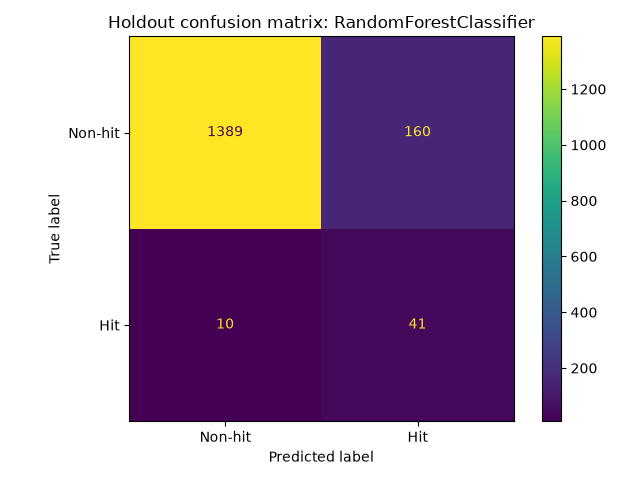

In [3]:
import json
selection = json.loads(ctx.path('metrics', 'classification_selection.json').read_text())
print('Chosen using training CV:', selection['model'])
display(Image(filename=str(ctx.path('plots', 'classification_confusion_matrix.png'))))

Read hit precision (how many shortlisted songs are hits), hit recall (how many real hits are found), F1 and average precision alongside accuracy. Confusion matrix rows are actual labels; columns are predicted labels. Every saved Joblib artifact contains all required preprocessing.